In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [629]:
m = 15
n = 10
# 

A = np.random.normal(size=(m,n))
L = np.random.normal(size=(k,n))
b = np.random.normal(size=m)

In [760]:
def flexible_golub_kahan(A, b, k):
    """Flexible Golub-Kahan.
    """
    m, n = A.shape
    # k = L.shape[0]

    U = np.zeros((m, k+1))
    T = np.zeros((k,k))
    M = np.zeros((k+1,k))
    Z = np.zeros((n,k))
    V = np.zeros((n, k))

    u = b/np.linalg.norm(b)
    U[:,0] = u.copy()
    broke_down = False
    broke_idx = None

    for i in range(k):
        w = A.T @ U[:,i]
        for j in range(i):
            T[j,i] = np.dot(w, V[:,j])
        
        for j in range(i):
            w -= T[j,i]*V[:,j]
        
        t = np.linalg.norm(w)
        print(t)
        T[i,i] = t
        V[:,i] = w/t

        Z[:,i] = V[:,i]
        w = A @ Z[:,i]
        for j in range(i+1):
            M[j,i] = np.dot(w, U[:,j])

        for j in range(i+1):
            w -= M[j,i]*U[:,j]

        m = np.linalg.norm(w)
        if np.abs(m) < 1e-15:
            broke_down = True
            broke_idx = i
            U = U[:,:i+1]
            M = M[:i+1,:i]
            T = T[:i,:i]
            Z = Z[:,:i]
            V = V[:,:i]
            break
            
        M[i+1,i] = m
        U[:,i+1] = w/m
        
    data = {
        "U": U,
        "T": T,
        "M": M,
        "Z": Z,
        "V": V,
        "broke_down": broke_down,
        "broke_idx": broke_idx,
    }
    
    return data


In [761]:
data = flexible_golub_kahan(A, b, 12)

3.540980017577359
3.276897455316121
2.8464407159024563
3.170388819359005
3.7476863997937744
2.320631074540893
2.8366766321309127
1.2292629419694874
1.4974902820848996
0.4354271851245936
1.506276446740307e-14


In [762]:
np.linalg.norm( (A @ data["Z"]) - (data["U"] @ data["M"])    )

1.2261488897762124e-15

In [763]:
print(data["broke_idx"])

10


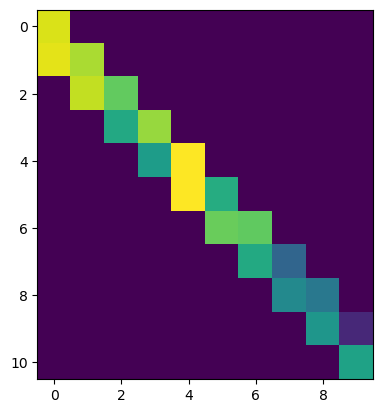

In [764]:
plt.imshow(data["M"])
plt.show()

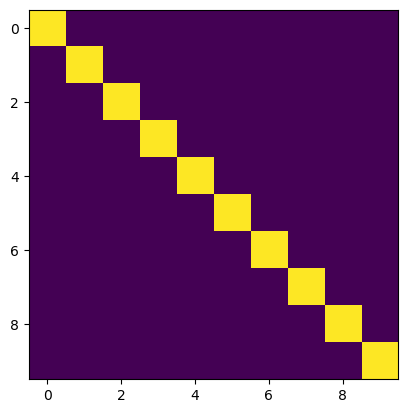

In [765]:
plt.imshow(data["V"].T @ data["V"])
plt.show()

In [766]:
np.linalg.norm( (data["V"].T @ data["V"]) - np.eye(data["V"].shape[1]) )

1.0237270844768904e-14

In [767]:
np.linalg.norm( (data["U"].T @ data["U"]) - np.eye(data["U"].shape[1]) )

2.755431101355196e-15

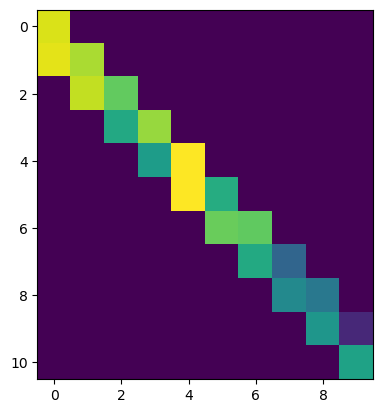

In [768]:
plt.imshow(data["M"])

In [769]:
data["U"].shape

(15, 11)

In [770]:
data["M"].shape

(11, 10)

In [771]:
data["Z"].shape

(10, 10)

In [772]:
A.shape

(15, 10)

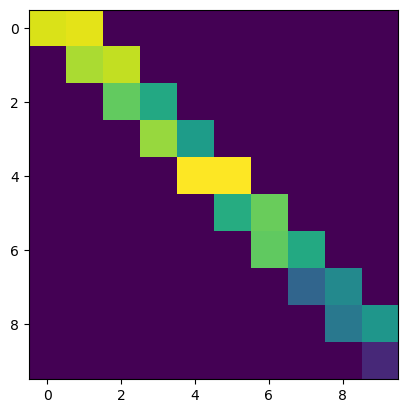

In [773]:
plt.imshow(data["T"])

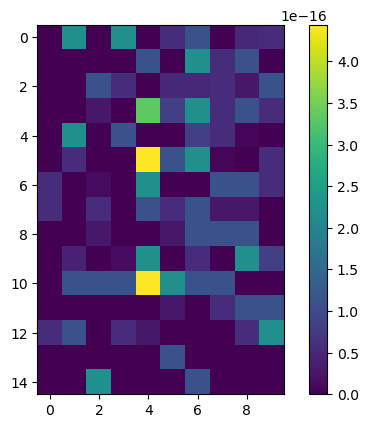

In [774]:
plt.imshow( np.abs( (A @ data["Z"]) - (data["U"] @ data["M"]) ) )
plt.colorbar()
plt.show()

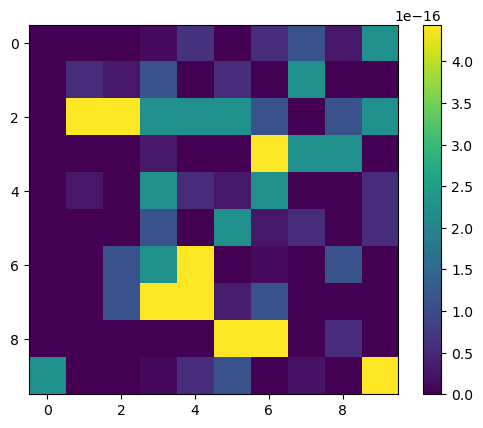

In [784]:
plt.imshow( np.abs( (A.T @ data["U"][:,:-1]) - (data["V"] @ data["T"]) ) )
plt.colorbar()
plt.show()

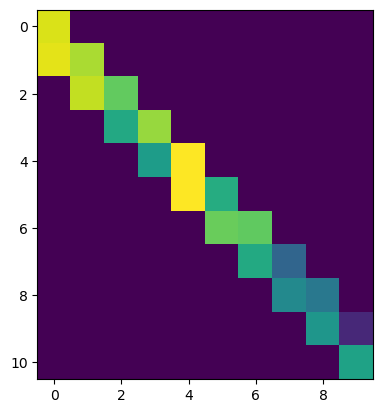

In [785]:
plt.imshow(data["M"])
plt.show()

In [786]:
A.shape

(15, 10)

In [788]:
data["Z"].shape

(10, 10)

In [789]:
data["U"].shape

(15, 11)

In [791]:
data["V"].shape

(10, 10)

In [780]:
data["M"].shape

(11, 10)

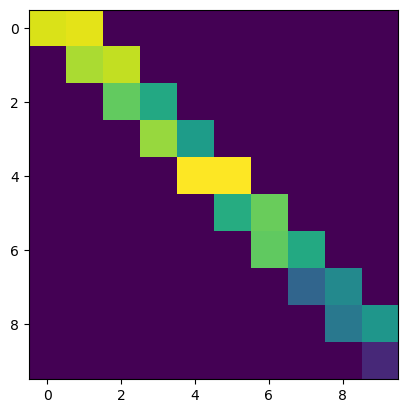

In [792]:
plt.imshow(data["T"])
plt.show()

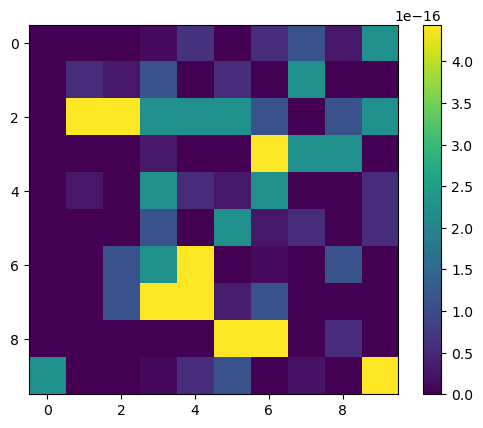

In [793]:
plt.imshow( np.abs( (A.T @ data["U"][:,:-1]) - (data["V"] @ data["T"]) ) )
plt.colorbar()
plt.show()

In [794]:
data["V"] @ data["T"]

array([[ 2.06808291,  1.90978016,  0.13567633, -0.06783126,  0.03476783,
         0.62731724, -0.06490682, -0.83884323,  0.04219371,  1.05911423],
       [-0.5946971 ,  0.45062903,  0.17848634, -0.21218251,  0.12725895,
        -0.28296846, -1.92147284, -1.82673685, -1.13086913, -0.69464033],
       [ 0.66913979,  2.78439654,  1.48305243, -1.83009536, -1.82161978,
        -1.65652386, -0.92105783,  0.26200941,  0.91971727,  0.53328361],
       [-0.01832232, -1.12521674, -2.04033644, -0.19142273,  0.7796871 ,
         0.8391128 , -1.03215836, -0.65675495,  1.42072217,  0.69565982],
       [ 0.55857822,  0.13144695, -2.3070804 , -1.52882647, -0.45872208,
         0.20634147,  1.92269758,  1.2338209 ,  0.09688145, -0.31433476],
       [ 1.5674558 ,  1.16564156, -1.1414516 ,  0.28062144, -1.00288476,
        -1.51242665,  0.18399496, -0.39737376, -0.80721845, -0.34545288],
       [-0.21247013, -0.3446229 ,  0.94037683,  1.68948379, -2.36395057,
        -2.71712972, -0.04877612,  0.15180356

In [719]:
data["T"]

array([[ 3.54098002e+00,  3.59091441e+00,  5.38751787e-16,
        -1.06028646e-15,  1.82778846e-15],
       [ 0.00000000e+00,  3.27689746e+00,  3.39888132e+00,
        -4.45375611e-16,  1.01878564e-15],
       [ 0.00000000e+00,  0.00000000e+00,  2.84644072e+00,
         2.26760809e+00, -1.68183168e-15],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         3.17038882e+00,  2.07854955e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  3.74768640e+00]])

In [795]:
data["V"].shape

(10, 10)

In [796]:
data["U"].shape

(15, 11)

In [797]:
data["V"].shape

(10, 10)

In [798]:
data["T"].shape

(10, 10)

In [799]:
(data["V"] @ data["T"]).shape

(10, 10)

In [210]:
(A.T @ data["U"]).shape

(10, 11)

In [166]:
data["broke_idx"]

10

In [167]:
data["U"].shape

(15, 10)

# Incremental version

In [973]:
def update_fgk(A, Z, U, M, V, T, L, breakdown_tol=1e-14):
    """Updates a FGK factorization by one step."""

    broke_down = False

    k = U.shape[1]
    v = A.T @ U[:,-1]
    assert k > 0, "invalid U"
    if k == 1:
        w = A.T @ U[:,-1]
        T = np.zeros((1,1))
        M = np.zeros((2,1))
    else:
        T = np.pad(T, ((0, 1), (0, 1)), mode='constant', constant_values=0)
        M = np.pad(M, ((0, 1), (0, 1)), mode='constant', constant_values=0)

        for j in range(k-1):
            T[j,k-1] = np.dot(V[:,j], v)
            v = v - T[j,k-1]*V[:,j]
            
    T[k-1,k-1] = np.linalg.norm(v)
    # Check for breakdown
    if np.abs(T[k-1,k-1]) < breakdown_tol:
        broke_down = True
        return U, M[:-1,:-1], T[:-1,:-1], V, Z, broke_down

    v = v/T[k-1,k-1]

    z = L @ v
    u = A @ z
    for j in range(k):
        M[j,k-1] = np.dot(U[:,j], u)
        u -= M[j,k-1]*U[:,j]

    M[k,k-1] = np.linalg.norm(u)

    # Check for breakdown
    if np.abs(M[k,k-1]) < breakdown_tol:
        broke_down = True
        return U, M[:-1,:-1], T[:-1,:-1], V, Z, broke_down

    u = u/M[k,k-1]

    if k == 1:
        V = v[:,None]
        Z = z[:,None]
    else:
        V = np.column_stack((V,v))
        Z = np.column_stack((Z,z))

    U = np.column_stack((U,u))

    return U, M, T, V, Z, broke_down

In [1002]:
m = 15
n = 10

A = np.random.normal(size=(m,n))
# L = np.random.normal(size=(k,n))
L = np.eye(n)
b = np.random.normal(size=m)

In [1004]:
u = b/np.linalg.norm(b)
U = u[:,None]

L = (1 + np.random.uniform())*np.eye(n)
U, M, T, V, Z, broke = update_fgk(A, None, U, None, None, None, L  )
for j in range(25):
    L = (100 + np.random.uniform())*np.eye(n)
    U, M, T, V, Z, broke = update_fgk(A, Z, U, M, V, T, L )
    if broke:
        print("broke")


broke
broke
broke
broke
broke
broke
broke
broke
broke
broke
broke
broke
broke
broke
broke


In [1005]:
np.linalg.norm( (A @ Z).flatten() - (U @ M).flatten() )

2.2006676737890367e-13

In [1006]:
np.linalg.norm( (A.T @ U[:,:-1]).flatten() - (V @ T).flatten() )

1.326849152447568e-15

In [1007]:
np.linalg.norm(  (V.T @ V) - np.eye(V.shape[1])  )

1.4142135623730951

In [1008]:
np.linalg.norm(  (U.T @ U) - np.eye(U.shape[1])  )

1.07704176977538